<a href="https://colab.research.google.com/github/OmkarA2004/Lab-Works/blob/main/1RV24BT040_Phylogenetic_Tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
!pip install -q biopython matplotlib

In [12]:
from google.colab import files

uploaded = files.upload()

if not uploaded:
    raise ValueError("No file uploaded. Please select your alignment file.")

filename = next(iter(uploaded))

print("Uploaded successfully:", filename)

Saving clustalw.phy to clustalw.phy
Uploaded successfully: clustalw.phy


In [13]:
import io
from Bio import AlignIO

with open(filename, "r", encoding="utf-8-sig") as f:
    file_content = f.read()

first_line = next(
    (line.strip() for line in file_content.splitlines() if line.strip()),
    ""
)

if first_line.upper().startswith("CLUSTAL"):
    formats = ["clustal"]
elif first_line.startswith(">"):
    formats = ["fasta"]
else:
    formats = ["phylip-relaxed", "phylip"]

alignment = None
detected_format = None
errors = []

for fmt in formats:
    try:
        alignment = AlignIO.read(io.StringIO(file_content), fmt)
        detected_format = fmt
        break
    except Exception as e:
        errors.append(f"{fmt}: {e}")

if alignment is None:
    raise ValueError(
        "Could not read your alignment file:\n" + "\n".join(errors)
    )

print("Format:", detected_format)
print("Total sequences:", len(alignment))
print("Alignment length:", alignment.get_alignment_length())

print("\nSpecies names:")

for record in alignment:
    print(record.id)

Format: phylip-relaxed
Total sequences: 5
Alignment length: 24142

Species names:
Mus
Rattus
Homo
Bos
Gallus


In [14]:
from Bio.Phylo.TreeConstruction import (
    DistanceCalculator,
    DistanceTreeConstructor
)

if len(alignment) != 5:
    raise ValueError(
        f"Expected 5 sequences, but found {len(alignment)}. "
        "Please upload an alignment containing all 5 species."
    )

calculator = DistanceCalculator("identity")

distance_matrix = calculator.get_distance(alignment)

print("Evolutionary distance matrix:")
print(distance_matrix)

Evolutionary distance matrix:
Mus 0.000000
Rattus  0.013545    0.000000
Homo    0.052605    0.051777    0.000000
Bos 0.944288    0.945282    0.936584    0.000000
Gallus  0.505799    0.507000    0.499213    0.815881    0.000000
    Mus Rattus  Homo    Bos Gallus


In [15]:
constructor = DistanceTreeConstructor()

tree = constructor.nj(distance_matrix)

print("Neighbor-Joining tree generated successfully!")

print("\nTree structure:")
from Bio import Phylo

Phylo.draw_ascii(tree)

Neighbor-Joining tree generated successfully!

Tree structure:
  , Mus
 ,|
 || Rattus
 |
_| Homo
 |
 |                      _____________ Gallus
 |_____________________|
                       |_______________________________________________ Bos



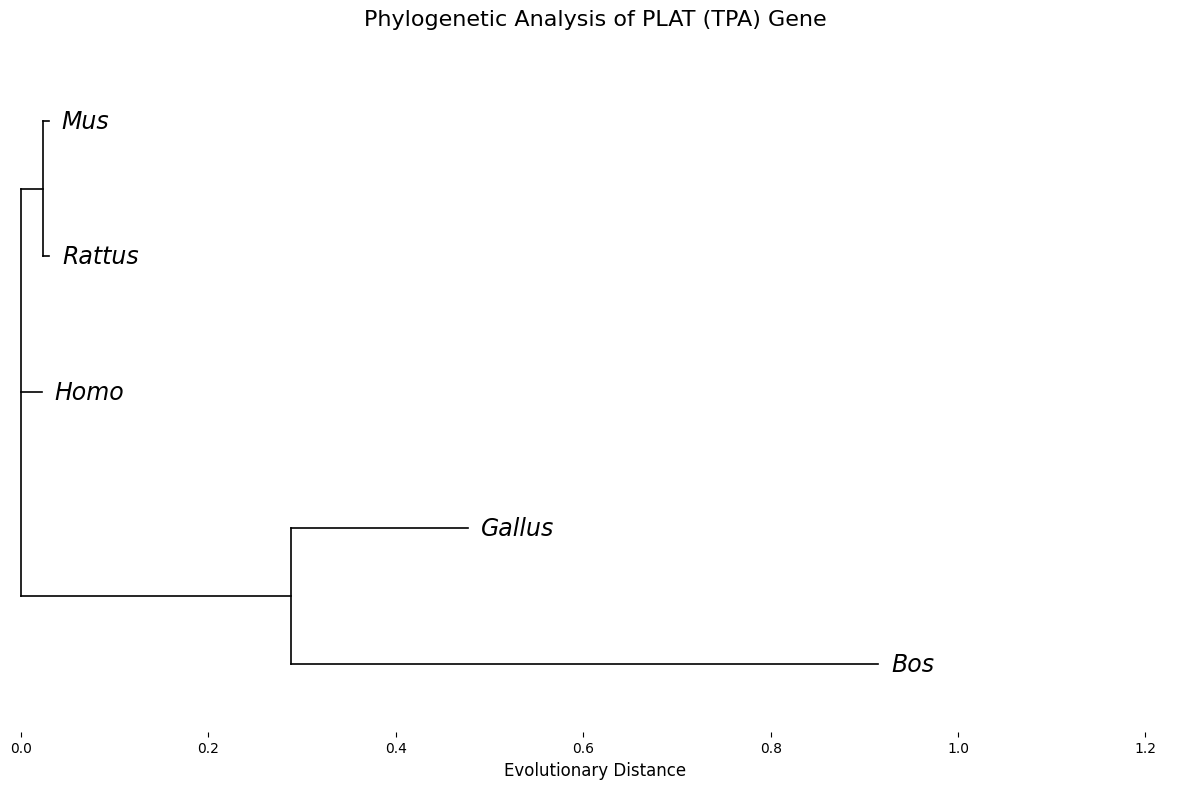

In [16]:
import matplotlib.pyplot as plt


terminals = tree.get_terminals()


y_positions = {
    terminal: i
    for i, terminal in enumerate(terminals)
}


def get_y(clade):
    if clade in y_positions:
        return y_positions[clade]

    child_positions = [get_y(child) for child in clade.clades]

    y_positions[clade] = sum(child_positions) / len(child_positions)

    return y_positions[clade]



x_positions = {}

def get_x(clade, parent_x=0):
    x_positions[clade] = parent_x

    for child in clade.clades:
        branch_length = child.branch_length or 0
        get_x(child, parent_x + max(0, branch_length))


get_x(tree.root)


fig, ax = plt.subplots(figsize=(12, 8))

def draw_clade(clade):
    children = clade.clades

    if not children:
        return

    parent_x = x_positions[clade]
    child_ys = [get_y(child) for child in children]


    ax.plot(
        [parent_x, parent_x],
        [min(child_ys), max(child_ys)],
        color="black",
        linewidth=1.2
    )

    for child in children:
        child_x = x_positions[child]
        child_y = get_y(child)


        ax.plot(
            [parent_x, child_x],
            [child_y, child_y],
            color="black",
            linewidth=1.2
        )

        draw_clade(child)



get_y(tree.root)

draw_clade(tree.root)


max_x = max(x_positions.values())

for terminal in terminals:
    ax.text(
        x_positions[terminal] + max(max_x * 0.015, 0.002),
        get_y(terminal),
        terminal.name or "Unknown",
        fontsize=17,
        fontstyle="italic",
        va="center",
        color="black"
    )


ax.set_title(
    "Phylogenetic Analysis of PLAT (TPA) Gene",
    fontsize=16,
    pad=20
)

ax.set_xlim(left=min(x_positions.values()) - 0.01,
            right=max_x + max(max_x * 0.35, 0.05))

ax.set_ylim(-0.5, len(terminals) - 0.5)
ax.invert_yaxis()

ax.set_xlabel("Evolutionary Distance", fontsize=12)
ax.set_yticks([])

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_facecolor("white")
fig.patch.set_facecolor("white")

plt.tight_layout()

plt.savefig(
    "PLAT_Phylogenetic_Tree.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()